# 54장 · SQL 매개변수 바인딩과 트랜잭션

SQL 매개변수는 쿼리의 자리표시자에 값을 별도로 전달합니다. 트랜잭션에서는 변경을 확정하기 전에 되돌릴 수 있습니다.

alice가 초안의 제목을 바꿨습니다. 바뀐 값을 읽은 직후라도 아직 확정하지 않았다면 되돌릴 수 있습니다. 이번에는 행을 넣고 값을 묶어서 보내는 방법과 변경을 확정하는 시점을 각각 살펴봅니다.

실행을 확인한 커널은 Python 3.12.15입니다.

Python 3 커널을 선택하고 위에서부터 실행하세요. 과제 셀에 직접 코드를 작성한 뒤 바로 아래에서 풀이를 펼쳐 보세요.


## WHERE에 문서 ID와 소유자 조건 결합

강의 원자료와 같은 문서 ID로 작은 SQLite 메모리 표를 준비합니다. 쿼리 문자열의 ?는 SQLite용 값 자리입니다. 입력값을 SQL 문장에 직접 이어 붙이지 않고 별도 튜플로 넘깁니다. PostgreSQL의 psycopg에서는 이 자리를 %s로 씁니다.


### 같은 문서 ID로 소유자만 바꾼 두 조회

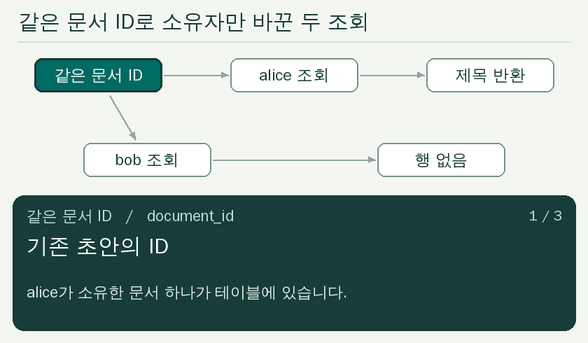

get_title에 같은 doc_id를 넣고 전달하는 사용자만 바꿔 두 번째 조건이 결과에 미치는 영향을 따라갑니다.


### 셀 01 · INSERT로 초안 저장

초기 자료는 커밋합니다. 이 셀을 다시 실행하면 모든 실습 값이 처음으로 돌아갑니다.


In [1]:
import sqlite3
db = sqlite3.connect(":memory:")
db.execute("CREATE TABLE course_documents (id TEXT PRIMARY KEY, owner TEXT NOT NULL, title TEXT NOT NULL, content TEXT)")
doc_id = "54000000-0000-4000-8000-000000000001"
owner = "alice"
db.execute("INSERT INTO course_documents VALUES (?, ?, ?, ?)", (doc_id, owner, "초안", "SQL 변경 연습입니다."))
db.commit()

def get_title(user, document_id):
    row = db.execute("SELECT title FROM course_documents WHERE id = ? AND owner = ?", (document_id, user)).fetchone()
    return row[0] if row else None

print(get_title('alice', doc_id))

초안


초안이 보입니다. 문서 ID가 같아도 WHERE 조건의 owner가 다르면 같은 행을 읽을 수 없습니다. 실제 서비스의 owner는 인증을 마친 요청에서 정해야 합니다.


### 문서 한 건을 담는 테이블

<p>course_documents의 id는 문서 한 건을 구별합니다. title과 content에는 각각 제목과 본문을 저장하고 owner에는 소유자를 저장합니다. 첫 셀이 초안을 넣고 commit한 뒤에는 이 행을 기준으로 수정 전후를 비교할 수 있습니다.</p>


### 테이블이 저장을 거부하는 값

<p>이 예제에서 id는 PRIMARY KEY이고 title과 owner에는 NOT NULL이 붙습니다. 같은 문서 ID를 다시 저장하거나 제목에 NULL을 넣으면 제약 위반입니다. owner 열에는 별도의 외래키가 선언되어 있지 않습니다.</p>


### 과제 02 · WHERE로 소유자 범위 제한

같은 문서 ID를 bob의 범위로 조회하세요. 행이 없을 때 함수가 반환하는 값을 표시합니다.


In [2]:
# get_title에 다른 사용자 ID를 전달하세요.

<details><summary>정답 코드와 실행 결과 보기</summary>
<pre><code>print(get_title(&#x27;bob&#x27;, doc_id))</code></pre>
<p>실행 결과</p><pre><code>None</code></pre>
<p>None입니다. 누락된 행을 정상적인 빈 결과로 다뤘습니다. 화면의 이름만 바꿔 다른 사용자의 문서를 보여 주지 않도록 조회 조건을 확인하세요.</p>
</details>


### 문서 ID와 소유자 두 조건의 효과

<p>같은 doc_id로 alice와 bob의 조회를 비교해 보세요. ID가 일치해도 owner 조건이 맞지 않으면 행을 얻지 못하고 get_title은 None을 반환합니다.</p>


## UPDATE와 rollback()

트랜잭션은 함께 확정하거나 되돌리는 변경의 단위입니다. UPDATE 직후 같은 연결에서는 바뀐 제목을 읽을 수 있습니다. 커밋 전에 롤백하면 앞서 커밋한 초안으로 돌아갑니다.

<!-- lesson-visual visual-tx -->
**rollback()이 되돌리는 값**

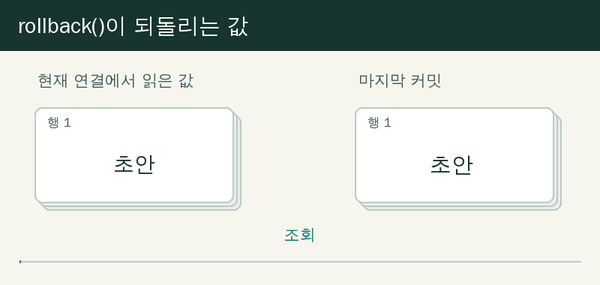

같은 연결에서는 UPDATE 직후 수정한 초안이 보입니다. 트랜잭션을 되돌리면 다시 조회한 제목은 마지막으로 확정된 초안입니다.
<!-- /lesson-visual visual-tx -->


### 셀 03 · UPDATE 직후 행 조회

아직 commit을 호출하지 않습니다.


In [3]:
db.execute("UPDATE course_documents SET title = ? WHERE id = ? AND owner = ?", ("수정한 초안", doc_id, owner))
print(get_title(owner, doc_id))

수정한 초안


수정한 초안입니다. 이 출력은 같은 연결에서 새 값을 읽었다는 증거이며 변경이 영구 저장됐다는 증거는 아닙니다.


### 문서를 새로 넣기와 제목 바꾸기

<p>INSERT는 새 ID와 소유자·제목·본문을 한 행으로 저장합니다. 뒤의 UPDATE는 WHERE에서 같은 문서 ID와 소유자를 모두 지정하고, 이미 있는 행의 title만 수정한 초안으로 바꿉니다.</p>


### 셀 04 · rollback()으로 변경 취소

위 셀 직후 rollback을 호출해 처음의 행을 다시 조회합니다.


In [4]:
db.rollback()
print(get_title(owner, doc_id))

초안


초안이 복구됩니다. UPDATE 직후에 commit을 넣으면 이어지는 rollback은 이미 확정한 변경을 되돌리지 못합니다.


### 마지막 커밋으로 돌아가기

<p>초안을 INSERT한 뒤 한 번 commit했습니다. 이어 UPDATE하면 같은 연결의 SELECT에는 수정한 초안이 보입니다. 여기서 rollback하면 마지막 커밋 이후의 UPDATE만 취소되어 문서 행은 남고 제목이 초안으로 돌아갑니다.</p>


### 과제 05 · DELETE의 조건 범위

alice가 가진 이 문서 한 건만 지운 뒤 조회하고, 연습이 끝나면 rollback으로 복원하세요.

삭제한 같은 행을 두 번 조회하세요. 첫 조회는 DELETE 직후, 두 번째는 rollback() 직후입니다. 문서 제목이 돌아왔는지는 두 번째 출력에서 확인합니다.


In [5]:
# DELETE에서 id와 owner를 모두 검사하세요.

<details><summary>정답 코드와 실행 결과 보기</summary>
<pre><code>db.execute(&quot;DELETE FROM course_documents WHERE id = ? AND owner = ?&quot;, (doc_id, owner))
print(get_title(owner, doc_id))
db.rollback()
print(get_title(owner, doc_id))</code></pre>
<p>실행 결과</p><pre><code>None
초안</code></pre>
<p>삭제 직후 첫 조회에는 행이 없습니다. 롤백 뒤 같은 소유자와 같은 ID로 다시 조회하면 원래 제목 ‘초안’이 보입니다.</p>
</details>


### DELETE와 대상 행 검사

<p>DELETE는 조건에 맞는 행을 지웁니다. 열 하나를 비우는 UPDATE와 다릅니다. 아래 문장은 오늘 만든 새 실습 문서 한 행만 대상으로 삼습니다. WHERE가 빠진 DELETE는 테이블의 모든 행을 대상으로 하므로 그대로 실행하지 않습니다.</p>

<p>sql/054_changes.sql은 BEGIN부터 COMMIT까지 한 묶음으로 제공합니다. 삽입한 제목은 초안, 수정 후 제목은 수정한 초안, 삭제 뒤 조회는 0행이 예상됩니다. 마지막에 행이 없는 이유는 오류로 되돌렸기 때문이 아니라, 묶음 안에서 그 행을 삭제하고 확정했기 때문입니다.</p>

<table><caption>세 명령 비교</caption><thead><tr><th scope="col">명령</th><th scope="col">바뀌는 것</th><th scope="col">실행 뒤 확인</th></tr>
</thead><tbody><tr><td>INSERT</td><td>새 행 추가</td><td>같은 ID 조회</td></tr>
<tr><td>UPDATE</td><td>조건에 맞는 행의 열 값</td><td>제목과 변경 행 수</td></tr>
<tr><td>DELETE</td><td>조건에 맞는 행 제거</td><td>같은 ID 조회가 0행인지</td></tr>
</tbody></table>


## 선택 실습 · PostgreSQL 값 바인딩

준비한 커널에서는 psycopg로 PostgreSQL의 임시 연습 표를 만듭니다. 실행 중 만든 표와 행은 트랜잭션 끝에 롤백합니다. 기본 연결은 53장에서 강사가 설정한 수업용 DB를 사용합니다.


### 셀 06 · 선택 실습 · 매개변수 바인딩

HK_COURSE_USE_POSTGRES=1과 수업용 연결이 준비되면 아래 블록이 실행됩니다. 저장소의 영구 테이블에는 쓰지 않습니다.


In [6]:
from importlib.util import find_spec
import os
pg_ready = find_spec("psycopg") is not None and os.getenv("HK_COURSE_USE_POSTGRES") == "1"
if pg_ready:
    import psycopg
    with psycopg.connect(connect_timeout=3) as conn:
        conn.execute("CREATE TEMP TABLE hk_note (id integer PRIMARY KEY, title text NOT NULL)")
        conn.execute("INSERT INTO hk_note VALUES (%s, %s)", (1, "조회문 복습"))
        value = conn.execute("SELECT title FROM hk_note WHERE id = %s", (1,)).fetchone()
        print(value[0])
        conn.rollback()
else:
    print("PostgreSQL 변경은 준비된 수업 커널에서 확인하세요.")

PostgreSQL 변경은 준비된 수업 커널에서 확인하세요.


실행한 PostgreSQL에서는 “조회문 복습”이 나와야 합니다. 접속 준비 안내는 PostgreSQL에서 변경이 성공했다는 뜻이 아닙니다. 앞에서 실행한 메모리 실습은 SQL 변경 순서를 확인한 결과입니다. 서버 실습에는 psycopg, 수업용 PostgreSQL 연결, 임시 테이블 생성 권한이 필요합니다. HK_COURSE_USE_POSTGRES=1인 수업 커널에서 실행한 뒤 바인딩한 제목과 다시 읽은 값을 비교하세요.


### 선택 셀의 PostgreSQL 연결

<p>이 셀은 psycopg가 설치되고 HK_COURSE_USE_POSTGRES 값이 1일 때 연결을 엽니다. 연결이 준비되면 임시 테이블 hk_note에서 값을 바인딩해 저장·조회하고 rollback합니다. 기본 SQLite 셀은 PostgreSQL 연결 없이도 실행할 수 있습니다.</p>


### SQLite의 ?와 Psycopg의 %s

<p>기본 셀의 sqlite3 쿼리는 값 자리에 ?를 씁니다. PostgreSQL 선택 셀에서는 psycopg가 %s를 사용합니다. 두 경우 모두 SQL과 전달할 값을 execute의 별도 인수로 넘깁니다. 자리 표시자가 달라도 문자열을 붙여 SQL을 만드는 과정은 없습니다.</p>


## 돌아보기

문서 등록과 질문 기록을 한 동작으로 묶을 때 두 번째 변경이 실패하면 첫 번째 변경도 되돌려야 할지 정하세요. 두 SQL문을 어느 트랜잭션에 넣을지 판단하는 근거가 됩니다.
